<a href="https://colab.research.google.com/github/Subhaashree06/JAVA-Assignments/blob/main/Java_CO3_Assignment3_Complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Java Programming Assignment 3 – CO3

**Student:** J.Subhaashree  
**Register number:** 192424008  



In [1]:
# 1. Setup
STUDENT_NAME = "J.Subhaashree"
REGISTER_NUMBER = "192424008"

import os, subprocess, textwrap, shutil, csv, json, time, zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("/content/CSA09-Assignment3")
if BASE.exists(): shutil.rmtree(BASE)
for x in ["Task01","Task02","Task03","Task04","Task05","Task06","Task07","data","graphs","logs","screenshots","reports"]:
    (BASE/x).mkdir(parents=True, exist_ok=True)

def write_java(task, name, source):
    p = BASE/task/name
    p.write_text(textwrap.dedent(source).strip()+"\n", encoding="utf-8")
    return p

def run_java(task, name, cls, timeout=60):
    folder=BASE/task
    c=subprocess.run(["javac",name],cwd=folder,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
    print(c.stdout)
    if c.returncode: raise RuntimeError("Compilation failed: "+name)
    r=subprocess.run(["java",cls],cwd=folder,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,timeout=timeout)
    (BASE/"logs"/(task+"_"+cls+".txt")).write_text(r.stdout,encoding="utf-8")
    print(r.stdout)
    if r.returncode: print("Runtime exit code:",r.returncode)
    return r.stdout

print(subprocess.run(["bash","-lc","java -version 2>&1; javac -version"],text=True,stdout=subprocess.PIPE).stdout)


[0.011s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.012s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12.1



## Q1 – ATM exception handling
Tests success, non-numeric input, negative amount, insufficient balance and missing card-reader file. The finally block executes on every transaction path.

In [2]:
q1 = r"""
import java.io.*;
class CardReaderException extends Exception { CardReaderException(String m){super(m);} }
class ATM {
 double balance=5000;
 void withdraw(String account,String text,boolean cardPresent) throws CardReaderException {
  try {
   if(!cardPresent) throw new FileNotFoundException("card-reader.dat missing");
   int amount=Integer.parseInt(text);
   if(amount<=0) throw new IllegalArgumentException("Amount must be positive");
   if(amount>balance) throw new IllegalStateException("Insufficient balance");
   balance-=amount;
   System.out.println("Withdrawal successful: "+amount+"; Balance: "+balance);
  } catch(FileNotFoundException e) {
   throw new CardReaderException("Card reader unavailable: "+e.getMessage());
  } finally { System.out.println("ATM transaction cleanup completed."); }
 }
}
public class ATMMain {
 public static void main(String[] args) {
  ATM atm=new ATM();
  String[][] tests={{"A100","500","true"},{"A101","abc","true"},{"A102","-50","true"},{"A103","9000","true"},{"A104","100","false"}};
  for(String[] t:tests) {
   System.out.println("--- Test "+t[0]+" ---");
   try {atm.withdraw(t[0],t[1],Boolean.parseBoolean(t[2]));}
   catch(CardReaderException|IllegalArgumentException|IllegalStateException e) {
    System.out.println("Caught: "+e.getClass().getSimpleName()+" - "+e.getMessage());
   }
  }
 }
}
"""
write_java("Task01","ATMMain.java",q1)
run_java("Task01","ATMMain.java","ATMMain")
(BASE/"Task01"/"test_cases.csv").write_text("test,account,amount,card_present,expected\\nT1,A100,500,true,success\\nT2,A101,abc,true,NumberFormatException\\nT3,A102,-50,true,IllegalArgumentException\\nT4,A103,9000,true,IllegalStateException\\nT5,A104,100,false,CardReaderException\\n")


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Test A100 ---
Withdrawal successful: 500; Balance: 4500.0
ATM transaction cleanup completed.
--- Test A101 ---
ATM transaction cleanup completed.
Caught: NumberFormatException - For input string: "abc"
--- Test A102 ---
ATM transaction cleanup completed.
Caught: IllegalArgumentException - Amount must be positive
--- Test A103 ---
ATM t

232

## Q2 – User-defined exceptions, propagation and chaining
Completes TODO 1 by wrapping the IOException in SubmissionStorageException and preserving the original cause.

In [3]:
q2=r"""
import java.io.IOException;
class ExamException extends Exception {
 ExamException(String m){super(m);}
 ExamException(String m,Throwable c){super(m,c);}
}
class SubmissionStorageException extends ExamException {
 SubmissionStorageException(String m,Throwable c){super(m,c);}
}
class Storage {
 void save(String fileName,long sizeKb) throws SubmissionStorageException {
  try {
   if(sizeKb>500) throw new IOException("Disk quota exceeded");
   System.out.println("Saved "+fileName);
  } catch(IOException e) {
   throw new SubmissionStorageException("Could not store "+fileName,e);
  }
 }
}
public class StorageDemo {
 public static void main(String[] args) {
  Storage s=new Storage();
  try {s.save("answer01.pdf",120);s.save("answer02.pdf",800);}
  catch(ExamException e) {
   System.out.println("Error: "+e.getMessage());
   System.out.println("Cause: "+e.getCause().getMessage());
   System.out.println("Cause type: "+e.getCause().getClass().getSimpleName());
  }
 }
}
"""
write_java("Task02","StorageDemo.java",q2)
run_java("Task02","StorageDemo.java","StorageDemo")


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.003s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.004s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Saved answer01.pdf
Error: Could not store answer02.pdf
Cause: Disk quota exceeded
Cause type: IOException



"[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\n[0.004s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\nSaved answer01.pdf\nError: Could not store answer02.pdf\nCause: Disk quota exceeded\nCause type: IOException\n"

## Q3 – Resource safety, debugging and try-with-resources
Creates three store files, injects a failure part-way through processing and compares manual closing with try-with-resources. The safe version closes each opened reader and the writer automatically.

In [4]:
q3=r"""
import java.io.*;
import java.nio.file.*;
public class ResourceReport {
 static void manual(Path d,Path out) {
  BufferedWriter w=null;
  try {
   w=Files.newBufferedWriter(out);
   for(int i=1;i<=3;i++) {
    BufferedReader r=Files.newBufferedReader(d.resolve("store"+i+".txt"));
    String line;while((line=r.readLine())!=null)w.write(line+"\n");
    r.close();
    if(i==2)throw new IOException("Injected failure after store2");
   }
  } catch(IOException e){System.out.println("Manual error: "+e.getMessage());}
  finally {if(w!=null)try{w.close();}catch(IOException e){System.out.println(e.getMessage());}}
 }
 static void safe(Path d,Path out) {
  try(BufferedWriter w=Files.newBufferedWriter(out)) {
   for(int i=1;i<=3;i++) {
    try(BufferedReader r=Files.newBufferedReader(d.resolve("store"+i+".txt"))) {
     String line;while((line=r.readLine())!=null)w.write(line+"\n");
    }
    if(i==2)throw new IOException("Injected failure after store2");
   }
  } catch(IOException e){System.out.println("Try-with-resources error: "+e.getMessage());}
 }
 public static void main(String[] args)throws Exception {
  Path d=Paths.get("input");Files.createDirectories(d);
  for(int i=1;i<=3;i++)Files.writeString(d.resolve("store"+i+".txt"),"Store "+i+",100\n");
  manual(d,Paths.get("manual_report.txt"));safe(d,Paths.get("safe_report.txt"));
  System.out.println("Manual output bytes: "+Files.size(Paths.get("manual_report.txt")));
  System.out.println("Safe output bytes: "+Files.size(Paths.get("safe_report.txt")));
 }
}
"""
write_java("Task03","ResourceReport.java",q3)
run_java("Task03","ResourceReport.java","ResourceReport")


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Manual error: Injected failure after store2
Try-with-resources error: Injected failure after store2
Manual output bytes: 24
Safe output bytes: 24



"[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\n[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\nManual error: Injected failure after store2\nTry-with-resources error: Injected failure after store2\nManual output bytes: 24\nSafe output bytes: 24\n"

## Q4 – Thread creation and thread life cycle
Uses both extending Thread and implementing Runnable. Runs ten experiments and records finish order; the order can differ because thread scheduling is nondeterministic.

In [5]:
q4=r"""
import java.util.*;
public class ThreadStations {
 static class ByThread extends Thread {
  int id;List<Integer> done;ByThread(int i,List<Integer>d){id=i;done=d;}
  public void run(){try{Thread.sleep(10+new Random().nextInt(60));}catch(InterruptedException e){interrupt();}synchronized(done){done.add(id);}}
 }
 static class ByRunnable implements Runnable {
  int id;List<Integer> done;ByRunnable(int i,List<Integer>d){id=i;done=d;}
  public void run(){try{Thread.sleep(10+new Random().nextInt(60));}catch(InterruptedException e){Thread.currentThread().interrupt();}synchronized(done){done.add(id);}}
 }
 public static void main(String[] args)throws Exception {
  for(int run=1;run<=10;run++){
   List<Integer> done=Collections.synchronizedList(new ArrayList<>());
   Thread[] ts=new Thread[4];ts[0]=new ByThread(1,done);
   for(int i=1;i<4;i++)ts[i]=new Thread(new ByRunnable(i+1,done));
   for(Thread t:ts)t.start();
   System.out.println("Run "+run+" station1 alive immediately? "+ts[0].isAlive());
   for(Thread t:ts)t.join();
   System.out.println("Run "+run+" finish order: "+done);
  }
  System.out.println("All stations completed after join().");
 }
}
"""
write_java("Task04","ThreadStations.java",q4)
out4=run_java("Task04","ThreadStations.java","ThreadStations")
orders=[x.split("finish order: ")[1] for x in out4.splitlines() if "finish order:" in x]
with open(BASE/"data"/"q4_thread_orders.csv","w",newline="") as f:
 w=csv.writer(f);w.writerow(["run","finish_order"]);w.writerows([[i+1,x] for i,x in enumerate(orders)])


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Run 1 station1 alive immediately? true
Run 1 finish order: [2, 4, 1, 3]
Run 2 station1 alive immediately? true
Run 2 finish order: [3, 2, 4, 1]
Run 3 station1 alive immediately? true
Run 3 finish order: [3, 4, 1, 2]
Run 4 station1 alive immediately? true
Run 4 finish order: [1, 3, 2, 4]
Run 5 station1 alive immediately? true
Run 5 finish o

## Q5 – Race conditions and synchronization
Completes the required TODO using a synchronized method. One hundred threads compete for ten seats; the expected result is exactly ten seats sold.

In [6]:
q5=r"""
public class SeatBooking {
 private final boolean[] booked;private int bookingsMade=0;
 SeatBooking(int seats){booked=new boolean[seats];}
 public synchronized void book(int seat){if(!booked[seat]){booked[seat]=true;bookingsMade++;}}
 public static void main(String[] args)throws InterruptedException {
  SeatBooking screen=new SeatBooking(10);Thread[] users=new Thread[100];
  for(int i=0;i<users.length;i++){final int seat=i%10;users[i]=new Thread(()->screen.book(seat));users[i].start();}
  for(Thread t:users)t.join();
  System.out.println("Seats sold: "+screen.bookingsMade);
 }
}
"""
write_java("Task05","SeatBooking.java",q5)
run_java("Task05","SeatBooking.java","SeatBooking")


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Seats sold: 10



"[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\n[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\nSeats sold: 10\n"

## Q6 – Deadlock prevention and producer-consumer
Completes TODO 1 and TODO 2 using while loops, wait() and notifyAll(). Also demonstrates deadlock prevention by acquiring wallet locks in a consistent ID order.

In [7]:
q6=r"""
public class TokenCounter {
 private final int[] buffer=new int[5];private int count=0,in=0,out=0;
 public synchronized void put(int token)throws InterruptedException {
  while(count==buffer.length)wait();
  buffer[in]=token;in=(in+1)%buffer.length;count++;notifyAll();
 }
 public synchronized int take()throws InterruptedException {
  while(count==0)wait();
  int token=buffer[out];out=(out+1)%buffer.length;count--;notifyAll();return token;
 }
 static class Wallet {final int id;int balance;Wallet(int i,int b){id=i;balance=b;}}
 static void transfer(Wallet a,Wallet b,int amount) {
  Wallet first=a.id<b.id?a:b,second=a.id<b.id?b:a;
  synchronized(first){synchronized(second){if(a.balance>=amount){a.balance-=amount;b.balance+=amount;}}}
 }
 public static void main(String[] args)throws InterruptedException {
  TokenCounter c=new TokenCounter();int[] sums=new int[2];
  Thread cook=new Thread(()->{try{for(int t=1;t<=20;t++)c.put(t);}catch(InterruptedException e){Thread.currentThread().interrupt();}});
  Thread[] students=new Thread[2];
  for(int s=0;s<2;s++){final int id=s;students[s]=new Thread(()->{try{for(int k=0;k<10;k++)sums[id]+=c.take();}catch(InterruptedException e){Thread.currentThread().interrupt();}});}
  cook.start();for(Thread t:students)t.start();cook.join();for(Thread t:students)t.join();
  System.out.println("Sum of tokens collected: "+(sums[0]+sums[1])+" (expected 210)");
  Wallet a=new Wallet(1,1000),b=new Wallet(2,1000);
  Thread x=new Thread(()->transfer(a,b,100)),y=new Thread(()->transfer(b,a,200));
  x.start();y.start();x.join();y.join();
  System.out.println("Wallet total: "+(a.balance+b.balance));
 }
}
"""
write_java("Task06","TokenCounter.java",q6)
run_java("Task06","TokenCounter.java","TokenCounter")


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Sum of tokens collected: 210 (expected 210)
Wallet total: 2000



"[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\n[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate\nSum of tokens collected: 210 (expected 210)\nWallet total: 2000\n"

## Q7 – Concurrent, fault-tolerant result processor
Generates 10,000 score-file cases, including corrupt and missing files. Uses ExecutorService, Callable, Future and ConcurrentLinkedQueue. Each task captures its own exception, so one bad file does not stop the complete run. Measures pool sizes 1, 2, 4 and 8.

In [9]:
q7=r"""
import java.io.*;import java.nio.file.*;import java.util.*;import java.util.concurrent.*;
public class ResultProcessor {
 static class R {String file;boolean ok;int score;String msg;R(String f,boolean o,int s,String m){file=f;ok=o;score=s;msg=m;}}
 static class Work implements Callable<R> {
  Path p;String n;Work(Path p,String n){this.p=p;this.n=n;}
  public R call(){
   try{
    if(!Files.exists(p))throw new FileNotFoundException("Missing score file");
    int score=Integer.parseInt(Files.readString(p).trim());
    if(score<0||score>100)throw new IllegalArgumentException("Score outside 0..100");
    long x=0;for(int i=0;i<20000;i++)x+=(i*31L)%97;
    return new R(n,true,score,"OK");
   }catch(Exception e){return new R(n,false,0,e.getClass().getSimpleName()+": "+e.getMessage());}
  }
 }
 public static void main(String[] args)throws Exception {
  Path d=Paths.get("scores");Files.createDirectories(d);
  for(int i=0;i<10000;i++){
   Path p=d.resolve(String.format("student_%05d.txt",i));
   if(i%100==0)Files.writeString(p,"corrupt");
   else if(i%100==1)Files.deleteIfExists(p);
   else Files.writeString(p,Integer.toString(i%101));
  }
  for(int pool:new int[]{1,2,4,8}){
   ExecutorService ex=Executors.newFixedThreadPool(pool);
   ConcurrentLinkedQueue<R> results=new ConcurrentLinkedQueue<>();
   List<Future<R>> futures=new ArrayList<>();long start=System.nanoTime();
   for(int i=0;i<10000;i++){String n=String.format("student_%05d.txt",i);futures.add(ex.submit(new Work(d.resolve(n),n)));}
   for(Future<R> f:futures)try{results.add(f.get());}catch(Exception e){results.add(new R("unknown",false,0,e.toString()));}
   ex.shutdown();long ms=(System.nanoTime()-start)/1000000;
   long ok=results.stream().filter(r->r.ok).count(),bad=results.size()-ok;
   System.out.println("Pool="+pool+", success="+ok+", failure="+bad+", time_ms="+ms);
   try(PrintWriter w=new PrintWriter("pool_"+pool+"_summary.csv")){
    w.println("file,success,score,message");for(R r:results)w.println(r.file+","+r.ok+","+r.score+",\""+r.msg.replace('"','\'')+"\"");
   }
   try(PrintWriter w=new PrintWriter("pool_"+pool+"_measurement.csv")){
    w.println("pool_size,total_files,successes,failures,time_ms");w.println(pool+","+results.size()+","+ok+","+bad+","+ms);
   }
  }
 }
}
"""
write_java("Task07","ResultProcessor.java",q7)
run_java("Task07","ResultProcessor.java","ResultProcessor",timeout=180)
for p in (BASE/"Task07").glob("*.csv"):shutil.copy2(p,BASE/"data"/p.name)

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Pool=1, success=9800, failure=200, time_ms=605
Pool=2, success=9800, failure=200, time_ms=211
Pool=4, success=9800, failure=200, time_ms=211
Pool=8, success=9800, failure=200, time_ms=163



## 8 – Measurement table and graph

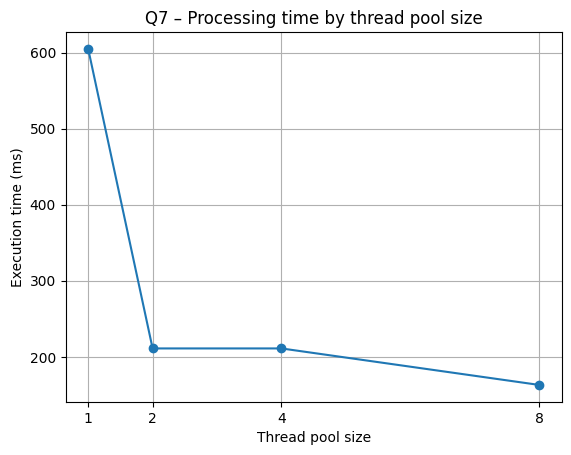

,pool_size,total_files,successes,failures,time_ms
0,1,10000,9800,200,605
1,2,10000,9800,200,211
2,4,10000,9800,200,211
3,8,10000,9800,200,163


In [10]:
parts=[]
for p in [1,2,4,8]:
    f=BASE/"data"/f"pool_{p}_measurement.csv"
    if f.exists(): parts.append(pd.read_csv(f))
perf=pd.concat(parts,ignore_index=True)
perf.to_csv(BASE/"data"/"q7_pool_benchmarks.csv",index=False)
plt.figure()
plt.plot(perf.pool_size,perf.time_ms,marker="o")
plt.xlabel("Thread pool size");plt.ylabel("Execution time (ms)")
plt.title("Q7 – Processing time by thread pool size")
plt.xticks([1,2,4,8]);plt.grid(True)
plt.savefig(BASE/"graphs"/"q7_pool_runtime.png",dpi=160,bbox_inches="tight")
plt.show()
display(perf)


## 9 – README and ZIP export


In [11]:
readme=f'''# Java Programming Assignment 3 – CO3
Student: {STUDENT_NAME}
Register number: {REGISTER_NUMBER}
Java version: Java 17 (runtime version shown in setup output)

## Task folders
Task01: ATM exception handling
Task02: User-defined exceptions and exception chaining
Task03: Resource safety and try-with-resources
Task04: Thread creation and life cycle
Task05: Race conditions and synchronization
Task06: Deadlock prevention and producer-consumer
Task07: Concurrent fault-tolerant result processing

Compile each source in its task folder using javac FileName.java and run using java ClassName.
See logs/ for outputs, data/ for raw CSV files and graphs/ for generated plots.
'''
(BASE/"README.md").write_text(readme,encoding="utf-8")
zip_path=Path("/content/Assignment3_Colab_Results.zip")
if zip_path.exists():zip_path.unlink()
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in BASE.rglob("*"):
        if p.is_file():z.write(p,p.relative_to(BASE.parent))
print("Created:",zip_path)
from google.colab import files
files.download(str(zip_path))


Created: /content/Assignment3_Colab_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>